# The Estimated Model
At this point, we can think of our parameter estimates either as those that minimise the sum of squared errors or, more generally, those values that maximise the likelihood (i.e. make the data most probable). As argued previously, the likelihood perspective is more universally applicable and so it is useful to think of the estimates in proabilistic terms. As such, if our data are truly drawn from a normal distribution then these parameter values make the data more likely than any other possible combination of values.

## The Final Estimates
Using the `mtcars` example again, after using either OLS or MLE (with REML for the variance) we have:

- $\hat{\beta}_{0} = 37.2851$
- $\hat{\beta}_{1} = -5.3445$
- $\hat{\sigma}^{2} = 9.2774$

This means that our final regression model can be expressed as [^bracket-foot]

$$
\text{MPG}_{i} = 37.2851 + (-5.3445 \times \text{Weight}_{i}) + e_{i}.
$$

The residuals can be calculated once values for $\hat{\beta}_{0}$ and $\hat{\beta}_{1}$ are available through a simple subtraction. If we take the *fitted* or *predicted* values of MPG to be

$$
\begin{align*}
    \widehat{\text{MPG}}_{i} &= \hat{\beta}_{0} + (\hat{\beta}_{1} \times \text{Weight}_{i}) \\  
                             &= 37.2851 + (-5.3445 \times \text{Weight}_{i})
\end{align*}
$$

then the residuals are simply

$$
e_{i} = \text{MPG}_{i} - \widehat{\text{MPG}}_{i},
$$

which is just the distance between the measured value of MPG and the point on the regression line for the corresponding value of Weight. We can also express this in terms of our probabilistic model like so

$$
\text{MPG}_{i} \sim \mathcal{N}\left(37.2851 + [-5.3445 \times \text{Weight}_{i}], 9.2774\right),
$$

though this starts to get a bit messy. Nevertheless, the point is that these estimates now complete every unknown element of the model.

## Simple Regression in `R`
The `R` function we use to fit a simple regression model is `lm()`, for *linear model*. We specify this model *symbolically* using the `R` formula interface, which we can think of as specialised syntax for the *mean function*. Because linear models have a constant variance, there is no option to specify any other variance function. In the example below, the model formula is given by `mpg ~ wt`, where the `~` symbol (called a *tilde*) is used to denote that `mpg` should be modelled as a function of `wt` [^equals-foot].

In order to fit the model, we call `lm()` and then save the estimated model to an object we call `mod` (though you can choose any name you like). This is shown below 

In [1]:
mod <- lm(mpg ~ wt, data=mtcars)

Inside `mod` are all the results from fitting the model. We can get a basic report of the model fit by simply printing the model object

In [2]:
print(mod)


Call:
lm(formula = mpg ~ wt, data = mtcars)

Coefficients:
(Intercept)           wt  
     37.285       -5.344  




and a much more detailed results table if we call `summary()` on the fitted object

In [3]:
summary(mod)


Call:
lm(formula = mpg ~ wt, data = mtcars)

Residuals:
    Min      1Q  Median      3Q     Max 
-4.5432 -2.3647 -0.1252  1.4096  6.8727 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)  37.2851     1.8776  19.858  < 2e-16 ***
wt           -5.3445     0.5591  -9.559 1.29e-10 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 3.046 on 30 degrees of freedom
Multiple R-squared:  0.7528,	Adjusted R-squared:  0.7446 
F-statistic: 91.38 on 1 and 30 DF,  p-value: 1.294e-10


We will discuss more about the specifics of this table over the rest of this unit. For now, we can see that the parameter estimates are given in the `Estimate` column of the table. The estimate of $\sigma$ is given below the table as the `Residual standard error`[^resstd-foot].

We can extract various bits of information from the model object. For instance, to get the estimates of the regression parameters we can use

In [4]:
print(coef(mod))

(Intercept)          wt 
  37.285126   -5.344472 


To get the *fitted values* we can use

In [5]:
print(fitted(mod))

          Mazda RX4       Mazda RX4 Wag          Datsun 710      Hornet 4 Drive   Hornet Sportabout 
          23.282611           21.919770           24.885952           20.102650           18.900144 
            Valiant          Duster 360           Merc 240D            Merc 230            Merc 280 
          18.793255           18.205363           20.236262           20.450041           18.900144 
          Merc 280C          Merc 450SE          Merc 450SL         Merc 450SLC  Cadillac Fleetwood 
          18.900144           15.533127           17.350247           17.083024            9.226650 
Lincoln Continental   Chrysler Imperial            Fiat 128         Honda Civic      Toyota Corolla 
           8.296712            8.718926           25.527289           28.653805           27.478021 
      Toyota Corona    Dodge Challenger         AMC Javelin          Camaro Z28    Pontiac Firebird 
          24.111004           18.472586           18.926866           16.762355           1

and to get the *residuals*, we can use

In [6]:
print(resid(mod))

          Mazda RX4       Mazda RX4 Wag          Datsun 710      Hornet 4 Drive   Hornet Sportabout 
         -2.2826106          -0.9197704          -2.0859521           1.2973499          -0.2001440 
            Valiant          Duster 360           Merc 240D            Merc 230            Merc 280 
         -0.6932545          -3.9053627           4.1637381           2.3499593           0.2998560 
          Merc 280C          Merc 450SE          Merc 450SL         Merc 450SLC  Cadillac Fleetwood 
         -1.1001440           0.8668731          -0.0502472          -1.8830236           1.1733496 
Lincoln Continental   Chrysler Imperial            Fiat 128         Honda Civic      Toyota Corolla 
          2.1032876           5.9810744           6.8727113           1.7461954           6.4219792 
      Toyota Corona    Dodge Challenger         AMC Javelin          Camaro Z28    Pontiac Firebird 
         -2.6110037          -2.9725862          -3.7268663          -3.4623553           2

Extracting the variance is a little more fiddly, but can be done using

In [7]:
sigma <- summary(mod)$sigma
print(sigma^2)

[1] 9.277398


or we can calculate it manually using

In [8]:
sigma2 <- sum(mod$residuals^2) / mod$df.residual
print(sigma2)

[1] 9.277398


## Interpreting the Estimates
So, we now have some numbers that correspond to our fitted model. Although we have focussed mainly on *how* to get these numbers, in practical terms our main interest is the *meaning* of these numbers. 

### The Slope
We start with the slope of the regression line because this is typically of *most* interest. In short, there are two elements of note for the slope: its *magnitude* and its *direction*. The magnitude is given by the actual numeric value of the slope. This is interpreted as the amount that $y$ changes for a *unit increase* in $x$. In context, this tells us how much MPG changes if we increase Weight by 1. Interpreting this therefore depends upon what a change of Weight by 1 actually means. For the `mtcars` dataset, `wt` is measured in units of 1,000 lbs. So a unit change for this variable corresponds to an *increase* in weight of 1,000 lbs. As such, our estimated slope indicates that an increase in weight of 1,000 lbs results in a change in average MPG of 5.3445. In addition, if we look at the *sign* of the estimate, we can infer the *direction* of this relationship. Because the estimate is *negative*, this corresponds to a *reduction* in MPG. So, for each additional 1,000 lbs of weight, MPG decreases by 5.3445.

Hopefully it is clear from this description that the parameter estimates are on the scale of the *outcome variable*, but depend upon the scale of the predictor for interpretation. If we changed the scaling of `wt` to actual measurements of lbs (by multiplying it by 1,000), the model fit would be the same, but the scale of the estimates would shift. In this case, a unit change would mean an increase in Weight of 1 lbs rather than 1,000 lbs. For instance

In [9]:
wt.scaled <- mtcars$wt*1000
summary(lm(mpg ~ wt.scaled, data=mtcars))


Call:
lm(formula = mpg ~ wt.scaled, data = mtcars)

Residuals:
    Min      1Q  Median      3Q     Max 
-4.5432 -2.3647 -0.1252  1.4096  6.8727 

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept) 37.2851262  1.8776273  19.858  < 2e-16 ***
wt.scaled   -0.0053445  0.0005591  -9.559 1.29e-10 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 3.046 on 30 degrees of freedom
Multiple R-squared:  0.7528,	Adjusted R-squared:  0.7446 
F-statistic: 91.38 on 1 and 30 DF,  p-value: 1.294e-10


### The Intercept
The intercept is often of less interest in a simple regression model. This is because its interpretation is usually uninteresting within the context of the data analysis. In addition, the value is often not very meaningful. For instance, in the context of the `mtcars` dataset, an intercept of 37.2851 can be interpreted as the predicted value of MPG for a  car that Weighs 0 lbs. This can be seen to fall out of the regression equation, as

$$
\begin{align*}
    E(y|x=0) &= \beta_{0} + \beta_{1}x \\ 
             &= \beta_{0} + (\beta_{1} \times 0) \\ 
             &= \beta_{0}
\end{align*}
$$

However, it should be clear that this estimate does not make much sense. A car that weights nothing should really have an MPG of 0, rather than an MPG of 37.2851. We will go into more detail about this in the associated workshop next week.

### The Variance
On its own, the estimated value of the variance is not that easy to interpret. We can, of course, take the square-root and arrive at the estimated standard deviation instead. In the `R` output, the estimated standard deviation is labelled in the summary table as the `Residual standard error`. We can also extract it with

In [10]:
print(summary(mod)$sigma)

[1] 3.045882


This means that, on average, the data deviates from the regression line by around 3.046 MPG. This is quite small on the scale of MPG, and so would seem quite good. However, on its own, we do not really have a way to interpret this value. In general, we treat the variance or standard deviation as a *relative* measure during the course of model building. We will see examples that formalise this more when we get to the concept of ANOVAs a little later on this unit.

## Visualising the Estimates
As a final part of this section, one of the most important things we can do to aid interpretation is to *visualise* the model. For simple regression, this means drawing the estimated regression line over a scatter plot of the data. This provides an immediate visual sense of all the numeric elements discussed above. 

The code below shows how to make a basic scatterplot with a regression line superimposed. We first create the scatterplot using the basic `plot()` function. We can then add the regression line using the `abline()` function, which has a useful `reg` option where we pass the model object and the line is drawn automatically.

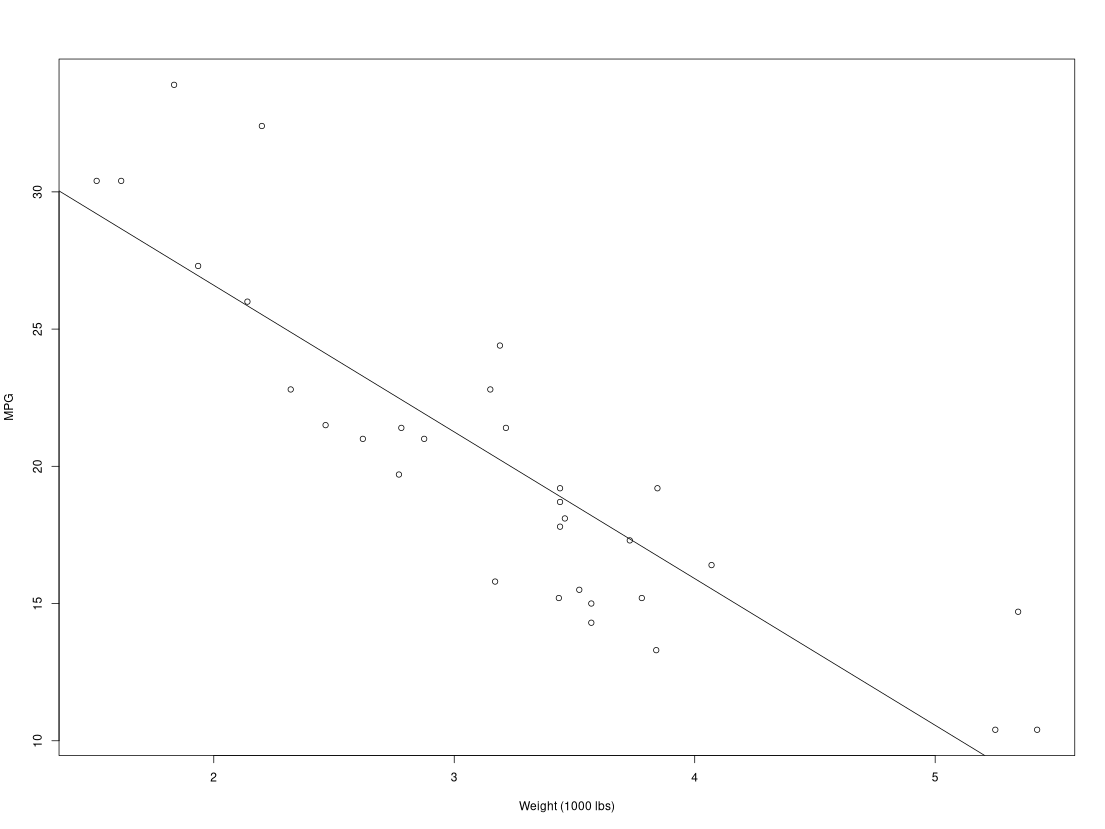

In [11]:
plot(x=mtcars$wt, y=mtcars$mpg, xlab="Weight (1000 lbs)", ylab="MPG")
abline(reg=mod)

This plot is not going to win any awards for visual style, but it is simple and effective as a quick means of drawing the model fit. It is the sort of plot we would use during the process of analysis, just to have a quick look. The key point is being able to *see* the model fit and assess it visually. This is one of the most important steps of building a statistical model as there is no substitute for *looking* at the data and seeing visually what your model is predicting.

`````{topic} What do you now know?
In this section, we have explored the results of estimating a simple regression model, either using OLS or using MLE (with REML for the variance). After reading this section, you should have a good sense of:

- How estimates can be used to complete the unknowns in the regression equation, producing both predicted (*fitted*) values and residuals.
- How the `R` formula interface can be used to specify the mean function of the model using `lm()`. 
- How to interpret some of the `R` output table from the `lm()` function, as well as how to extract some basic results from the model object.
- The meaning of the *slope* in terms of quantifying the change in $y$ for a unit-change in $x$.
- The meaning of the *intercept* in terms of quantifying the value of $y$ when $x = 0$.
- How the model fit can be visualised using some basic plots in `R`.
`````

[^bracket-foot]: We use the brackets here not because they are necessary, but because they help group together each variable and its corresponding parameter.

[^resstd-foot]: This is something of a misnomer, but is one of the quirks of `lm()` that has stuck around for many years.

[^equals-foot]: You may wonder, why not use the `=` symbol? The answer is that `=` already has a meaning in `R` for deifning named arguments within a function. For instance, we use `data=mtcars` as an argument inside `lm()`. So, another symbol is needed to prevent the parser from getting confused.